# Week 11: Solution

## Part 1: The inverse Fourier transform

Let us load the DFT and IDFT:

In [13]:
import numpy as np
import matplotlib.pyplot as plt

def my_DFT(X):
    N = len(X)

    if N%2 == 0:
        X = X[:-1]
        N -= 1
    
    F = np.fft.fft(X)

    myF = np.array([F[0].real/np.sqrt(N),])

    for k in range(1,int((N+1)/2)):
        myF = np.append(myF, F[k].real*np.sqrt(2/N))
        myF = np.append(myF, F[k].imag*np.sqrt(2/N))

    return myF

def my_DFT_amplitude(X):
    N = len(X)

    if N%2 == 0:
        X = X[:-1]
        N -= 1
    
    F = np.fft.fft(X)

    myF = np.array([F[0].real/np.sqrt(N),])

    for k in range(1,int((N+1)/2)):
        myF = np.append(myF, np.sqrt((F[k].real*np.sqrt(2/N))**2 + (F[k].imag*np.sqrt(2/N))**2))

    return myF

def plot_DFT(myF):
    N = len(myF)

    c = myF[1::2]
    s = myF[2::2]
    x = [myF[0]] + [np.sqrt(c[i]**2 + s[i]**2) for i in range((N-1)/2)]

    fig, ax = plt.subplots(figsize=(7,3))

    ax.plot(range((N-1)/2), x, 'o', color='C2')
    ax.set_xlabel('k')
    ax.set_ylabel('magnitude')

    plt.tight_layout()
    plt.show()

    import numpy as np

def my_IDFT(myF):
    N = len(myF)            # recover odd N from coefficient length
    half = (N + 1) // 2             # positive frequencies stored: k = 1:(N-1)/2

    F = np.empty(N, dtype=complex)

    # invert the scalings
    F[0] = myF[0] * np.sqrt(N)                                  # F[0] = myF[0]/(1/√N)
    F[1:half] = np.sqrt(N / 2) * (myF[1::2] + 1j * myF[2::2])   # Recreating the complex values

    # fill the conjugate-symmetric half: F[N-k] = conj(F[k])
    F[half:] = np.conj(F[N - half:0:-1])

    return np.fft.ifft(F).real

## Part 2: Filters
2. Compute the DFT of the 3001 first recordings of sensor `Af7.`

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

X = pd.read_csv('../files/S089R03.csv')['Af7.'][range(3001)]
Xt = my_DFT(X)

3. [Low-pass filter] In this DFT, keep the 251 first coefficients unchanged and set all the others to zero. 
   Then compute the IDFT (inverse DFT) and plot both the original time series and the output of the IDFT on the same figure.
   What do you observe?

3001


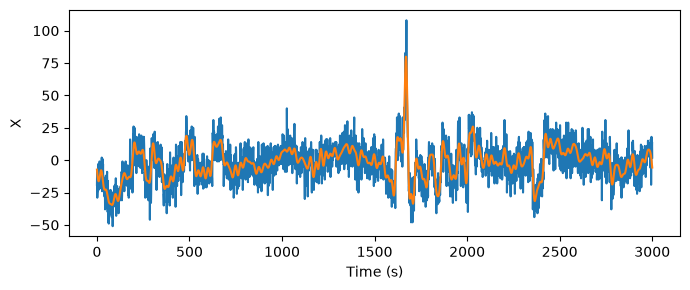

In [15]:
Xt1 = np.zeros(len(Xt))
Xt1[:251] = Xt[:251]

print(len(Xt1))

X1 = my_IDFT(Xt1)

fig, ax = plt.subplots(figsize=(7,3))

ax.plot(X)
ax.plot(X1)

ax.set_xlabel('Time (s)')
ax.set_ylabel('X')

plt.tight_layout()
plt.show()

4. [High-pass filter] In the DFT again, keep the 1000 last coefficents unchanged and set all the other to zero. 
   Computing and plotting the IDFT, what do you observe now. 

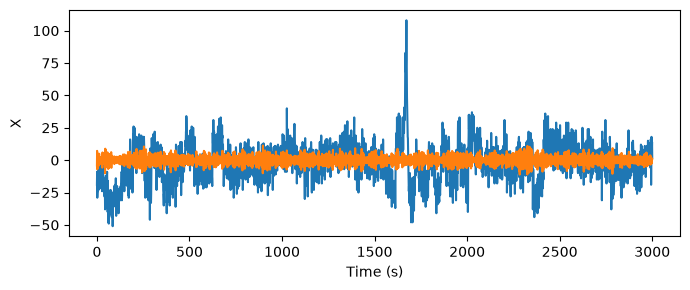

In [16]:
Xt2 = np.zeros(len(Xt))
Xt2[-1000:] = Xt[-1000:]

X2 = my_IDFT(Xt2)

fig, ax = plt.subplots(figsize=(7,3))

ax.plot(X)
ax.plot(X2)

ax.set_xlabel('Time (s)')
ax.set_ylabel('X')

plt.tight_layout()
plt.show()

5. [Band-pass filter] Identify now a peak half way in the spectrum. 
   Keep a narrow range of 100 coefficients aroung this peak unchanged and set all others to zero. 
   Again compute and plot the IDFT.

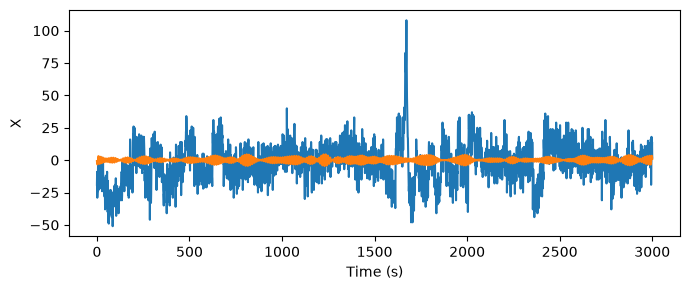

In [17]:
Xt3 = np.zeros(len(Xt))
Xt3[450:551] = Xt[450:551]

X3 = my_IDFT(Xt3)

fig, ax = plt.subplots(figsize=(7,3))

ax.plot(X)
ax.plot(X3)

ax.set_xlabel('Time (s)')
ax.set_ylabel('X')

plt.tight_layout()
plt.show()

A filter selects a frequency range and isolates the contribution of these frequencies to the time series. 
The contribution of all other frequencies is discarded. 

## Part 3: Thresholding
A filter focuses on a chosen frequency range. 
Sometimes, we want to cover all the frequency spectrum, but only keep the terms of the DFT which contribute the most to the time series' shape.

In this case, we choose a threshold $\gamma$ and keep only the coefficients of the DFT whose magnitude is larger that $\gamma$ 
All other coefficients are set to zero.
Finally, the IDFT is computed to get back to time domain.

This **thresholding** will smoothen the signal but the contribution of all relevant frequencies.

6. In the same DFT as before, keep the 30 largest coefficients and set all others to zero. 
   Compute and plot the IDFT.

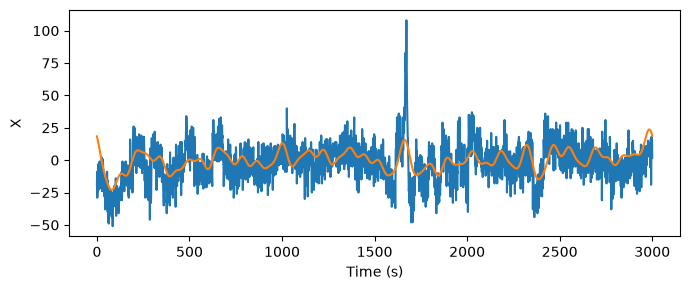

In [22]:
thr = sorted(np.abs(Xt))[-30]
Xt4 = np.array([x if x >= thr else 0 for x in Xt]) # Keep only the 30 largest values, set all others to zero.

X4 = my_IDFT(Xt4)

fig, ax = plt.subplots(figsize=(7,3))

ax.plot(X)
ax.plot(X4)

ax.set_xlabel('Time (s)')
ax.set_ylabel('X')

plt.tight_layout()
plt.show()

7. Repeat for the 100 largest coefficients. For the 300 largest coefficients. For the 1000 largest coefficients. 

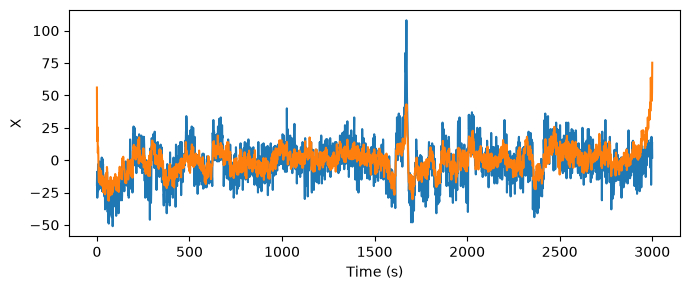

In [27]:
thr = sorted(np.abs(Xt))[-300]
Xt5 = np.array([x if x >= thr else 0 for x in Xt]) # Keep only the 300 largest values, set all others to zero.

X5 = my_IDFT(Xt5)

fig, ax = plt.subplots(figsize=(7,3))

ax.plot(X)
ax.plot(X5)

ax.set_xlabel('Time (s)')
ax.set_ylabel('X')

plt.tight_layout()
plt.show()